# AI Forecast 
## Предсказание погоды с помощью машинного обучения

Обучение моделей для предсказания погоды по временным рядам.<br>
Для обучения были собраны данные о погоде в двух городах: Москва и Санкт-Петербург.<br>


## Установка и импорт необходимых пакетов

In [1]:
!pip install -U --pre lightautoml==0.4.2 -q 2>/dev/null

In [2]:
import numpy as np
import pandas as pd

from pathlib import Path
import os

from matplotlib import pyplot as plt

from sklearn.metrics import f1_score
from sklearn.model_selection import train_test_split

from lightautoml.automl.presets.tabular_presets import TabularAutoML, TabularUtilizedAutoML
from lightautoml.tasks import Task
from lightautoml.report.report_deco import ReportDeco, ReportDecoUtilized
from lightautoml.addons.tabular_interpretation import SSWARM

import pickle

'nlp' extra dependency package 'fasttext-numpy2' isn't installed. Look at README.md in repo 'LightAutoML' for installation instructions.


In [3]:
#Импорты для kaggle
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))
import kagglehub

/kaggle/input/datasets/e1gris/msk-weather/daily.csv
/kaggle/input/datasets/e1gris/spb-weather/spb.csv


## Обработка данных

Предсказания моделей будут строиться на количестве выпавшего дождя для каждого дня из n лага. <br>
Далее будут рассмотренны два подхода: с кодированием осадков и без кодирования.

In [4]:
#Выбор города для создания модели

# mode = 'msk'
mode = 'spb'

In [5]:
#Датасеты
if mode == 'msk':
    #Погода в Москве 01.01.2005 – 31.12.2025
    path_to_dataset = "/kaggle/input/datasets/e1gris/msk-weather/daily.csv"
elif mode == 'spb':
    #Погода в Санкт-Петербурге 01.01.2005 – 31.12.2025
    path_to_dataset = "/kaggle/input/datasets/e1gris/spb-weather/spb.csv"

In [6]:
df = pd.read_csv(path_to_dataset)
df.sample(3)
for x in df.columns:
    print(x)
df.head()

time
temperature_2m_mean (°C)
surface_pressure_mean (hPa)
rain_sum (mm)
wind_speed_10m_mean (km/h)
wind_direction_10m_dominant (°)


,time,temperature_2m_mean (°C),surface_pressure_mean (hPa),rain_sum (mm),wind_speed_10m_mean (km/h),wind_direction_10m_dominant (°)
0,2000-01-01,-8.0,1020.2,0.0,4.2,65
1,2000-01-02,-9.2,1022.8,0.0,11.0,161
2,2000-01-03,-9.2,1012.5,0.0,18.5,146
3,2000-01-04,-2.3,997.3,1.1,21.0,194
4,2000-01-05,0.1,998.6,0.1,21.2,266


In [7]:
df = df[["time", "rain_sum (mm)"]].copy()

### Категориальный подход
Для подхода с разбиением уровня осадков на категории необходимо определить эти самые категорий:
* 0 - Нет осадков
* 1 - Меньше среднего
* 2 - Среднее значение
* 3 - Больше среднего

Точкой отсчета будет среднее значение.

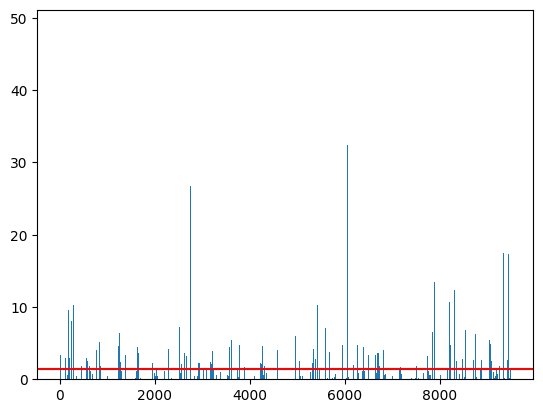

Среднее значение осадков 1.431367800358008 мм


In [8]:
def count_mean_rain_sum(df):
    rain_mm = df["rain_sum (mm)"].to_numpy()
    mean = rain_mm.mean()
    
    x = np.arange(len(rain_mm))
    plt.bar(x, rain_mm)
    plt.axhline(mean, color = "r")
    plt.show()
    
    print(f"Среднее значение осадков {mean} мм")

    return mean

mean = count_mean_rain_sum(df)

### Функция для кодирования
Так как значений равных среднему нет, либо их очень мало, взят диапазон ±0,5 мм.

In [9]:
def encode_rain(df):
    df1 = df.copy()
    for i in range(df1.shape[0]):
        rain = float(df1.iloc[i, 1])

        if rain == 0:
            continue
        elif rain - mean > 0.5:
            df1.iloc[i, 1] = 3 
        elif rain - mean < -0.5:
            df1.iloc[i, 1] = 1
        else:
            df1.iloc[i, 1] = 2

    # print(df1['rain_sum (mm)'].value_counts())

    return df1

In [10]:
def add_lags(df, lags_number):
    df2 = df.copy()
    for i in range(1, lags_number):
        df2[f'shift{i}'] = df2['rain_sum (mm)'].shift(i)
    df2 = df2.dropna()
    
    df2.rename(columns={'rain_sum (mm)': 'target'}, inplace=True)

    return df2

In [11]:
def split_data(df):
    df = df.copy()
    
    target = df["target"]
    df = df.drop(columns=["target"])
    target = (target != 0).astype(int)
    
    df = df.drop(columns=["time"])

    X_train, X_test, y_train, y_test = train_test_split(
    df, 
    target, 
    test_size=0.2, 
    shuffle=False,      
    random_state=42
    )

    return [X_train, X_test, y_train, y_test]

## Обучение модели
Лучшая модель будет выбрана в ходе серии экспериментов. Для разного колличества лагов будет обучено 2 модели: с катигориальным подходом и без. Лучшая модель будет сохранена. 

In [12]:
def train_model(df, number_of_lags, cat = False):
    
    df = df.copy()

    if cat == True:
        df = encode_rain(df)
        method = "Категориальный"
    else:
        method = "Оригинальные значения"

    df = add_lags(df, number_of_lags)

    X_train, X_test, y_train, y_test = split_data(df)
    
    train_data = X_train.copy()
    train_data['target'] = y_train
    
    task = Task('binary')
    roles = {
        'target': "target",
    }
    N_THREADS = 8
    RANDOM_STATE = 42
    N_FOLDS = 10
    
    automl = TabularAutoML(
        task = task,
        timeout = 36000,
        cpu_limit = N_THREADS,
        reader_params = {'n_jobs': N_THREADS, 'cv': N_FOLDS, 'random_state': RANDOM_STATE},
    )
    
    out_of_fold_predictions = automl.fit_predict(train_data, roles = roles, verbose = 0)
    
    test_predictions = automl.predict(X_test)
    probabilities = test_predictions.data[:, 0]
    
    threshold = 0.5
    binary_predictions = (probabilities > threshold).astype(int)
    
    f1 = f1_score(y_test, binary_predictions)

    return {"Model": automl, "number_of_lags": number_of_lags, "method": method, "f1": f1}
    

In [13]:
best_model = {"f1": -1}
history = {"cat": [], "orig": [], "lags": []}
for number_of_lags in range(5, 35, 5):

    print(f"number_of_lags = {number_of_lags}")
    
    cat_model = train_model(df, number_of_lags, True)
    orig_model = train_model(df, number_of_lags, False)

    history["cat"].append(cat_model["f1"])
    history["orig"].append(orig_model["f1"])
    history["lags"].append(number_of_lags)
    
    if cat_model["f1"] > orig_model["f1"]:
        model = cat_model
    else:
        model = orig_model

    if model["f1"] > best_model["f1"]:
        best_model = model

number_of_lags = 5
number_of_lags = 10
number_of_lags = 15
number_of_lags = 20
number_of_lags = 25
number_of_lags = 30


In [14]:
best_model_stats = best_model.copy()
best_model_stats.pop("Model", None)
print(best_model_stats)

{'number_of_lags': 30, 'method': 'Категориальный', 'f1': 0.7180031864046734}


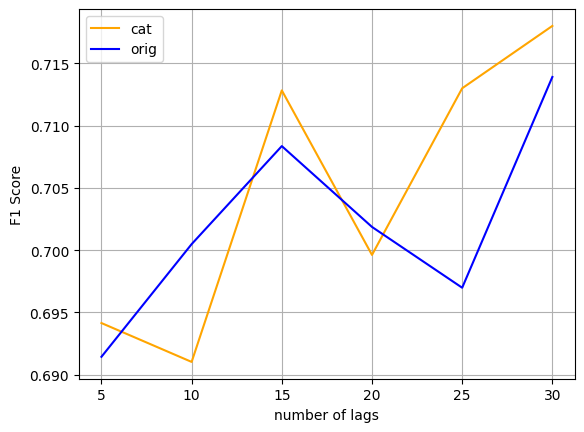

In [15]:
plt.plot(history["lags"], history["cat"], label = "cat", color = "orange")
plt.plot(history["lags"], history["orig"], label = "orig", color = "blue")

plt.xlabel("number of lags")
plt.ylabel("F1 Score")


plt.legend()
plt.grid()
plt.show()

In [16]:
Path("models").mkdir(parents=True, exist_ok=True)

with open(f'models/{mode}_model.pkl', 'wb') as f:
    pickle.dump(best_model["Model"], f)